In [25]:

# Project 1: Movie Recommendation System
# Step 1: Import required libraries

import os
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")



Libraries imported successfully!


In [26]:

# Step 2: Download and extract the dataset

url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"

os.makedirs("data", exist_ok=True)

zip_path = "data/movielens.zip"

urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("data")

print("Dataset downloaded and extracted successfully!")
print("Dataset folder:", "data/ml-latest-small")


Dataset downloaded and extracted successfully!
Dataset folder: data/ml-latest-small


In [27]:

# Step 3: Load movie and rating data

data_path = "data/ml-latest-small"

movies = pd.read_csv(f"{data_path}/movies.csv")
ratings = pd.read_csv(f"{data_path}/ratings.csv")

print("Movies dataset shape:", movies.shape)
print("Ratings dataset shape:", ratings.shape)

print("\nFirst 5 movies:")
display(movies.head())

print("\nFirst 5 ratings:")
display(ratings.head())


Movies dataset shape: (9742, 3)
Ratings dataset shape: (100836, 4)

First 5 movies:


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy



First 5 ratings:


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [28]:

# Step 4: Inspect missing values and duplicates

print("Missing values in movies:")
print(movies.isnull().sum())

print("\nMissing values in ratings:")
print(ratings.isnull().sum())

print("\nDuplicate movie records:", movies.duplicated().sum())
print("Duplicate rating records:", ratings.duplicated().sum())

print("\nRating range:")
print(ratings["rating"].min(), "to", ratings["rating"].max())


Missing values in movies:
movieId    0
title      0
genres     0
dtype: int64

Missing values in ratings:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Duplicate movie records: 0
Duplicate rating records: 0

Rating range:
0.5 to 5.0


In [29]:

# Step 5: Analyze movie ratings

# Average rating of each movie
movie_stats = ratings.groupby("movieId").agg(
    average_rating=("rating", "mean"),
    number_of_ratings=("rating", "count")
).reset_index()

# Add movie titles
movie_stats = movie_stats.merge(movies, on="movieId")

# Display popular movies with at least 50 ratings
popular_movies = movie_stats[
    movie_stats["number_of_ratings"] >= 50
].sort_values("average_rating", ascending=False)

print("Top 10 highly rated movies (minimum 50 ratings):")
display(
    popular_movies[
        ["title", "genres", "average_rating", "number_of_ratings"]
    ].head(10).round(2)
)


Top 10 highly rated movies (minimum 50 ratings):


,title,genres,average_rating,number_of_ratings
277,"Shawshank Redemption, The (1994)",Crime|Drama,4.43,317
659,"Godfather, The (1972)",Crime|Drama,4.29,192
2224,Fight Club (1999),Action|Crime|Drama|Thriller,4.27,218
974,Cool Hand Luke (1967),Drama,4.27,57
602,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,4.27,97
686,Rear Window (1954),Mystery|Thriller,4.26,84
921,"Godfather: Part II, The (1974)",Crime|Drama,4.26,129
6298,"Departed, The (2006)",Crime|Drama|Thriller,4.25,107
913,Goodfellas (1990),Crime|Drama,4.25,126
694,Casablanca (1942),Drama|Romance,4.24,100


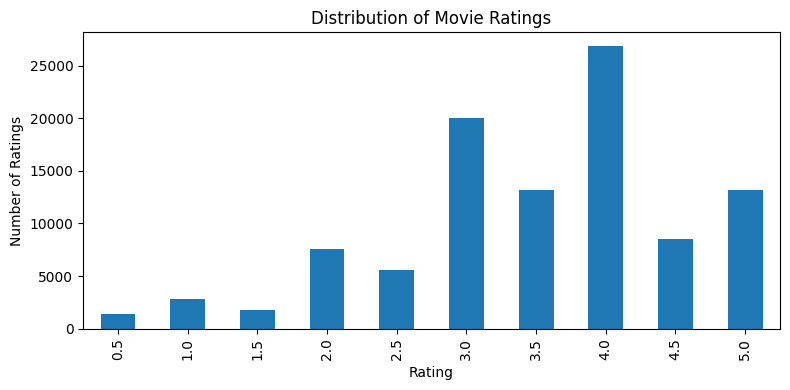

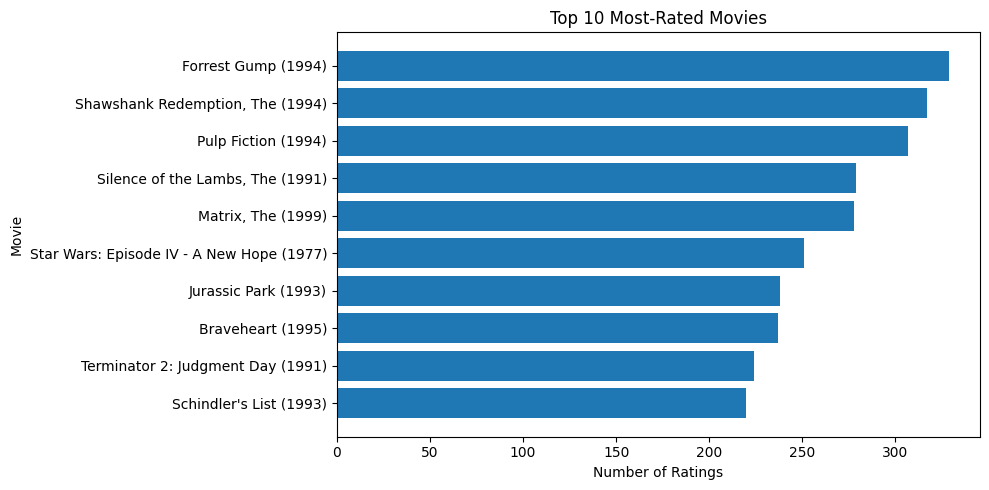

In [30]:

# Step 6: Visualize movie trends

# Rating distribution
plt.figure(figsize=(8, 4))
ratings["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.tight_layout()
plt.show()

# Most-rated movies
top_rated_count = movie_stats.sort_values(
    "number_of_ratings", ascending=False
).head(10)

plt.figure(figsize=(10, 5))
plt.barh(
    top_rated_count["title"].iloc[::-1],
    top_rated_count["number_of_ratings"].iloc[::-1]
)
plt.title("Top 10 Most-Rated Movies")
plt.xlabel("Number of Ratings")
plt.ylabel("Movie")
plt.tight_layout()
plt.show()


In [31]:

# Step 7: Build the recommendation system

# Create a user-movie ratings matrix
user_movie_matrix = ratings.pivot_table(
    index="userId",
    columns="movieId",
    values="rating"
)

# Calculate similarity between users based on their ratings
user_similarity = user_movie_matrix.T.corr(
    method="pearson", min_periods=5
)

def recommend_movies(user_id, n=10, min_common_ratings=3):
    if user_id not in user_movie_matrix.index:
        return f"User {user_id} was not found in the dataset."

    # Ratings from the selected user
    user_ratings = user_movie_matrix.loc[user_id]

    # Other users' similarity to this user
    similarities = user_similarity.loc[user_id].drop(
        labels=[user_id]
    ).dropna()

    # Select similar users with positive similarity
    similar_users = similarities[similarities > 0].sort_values(
        ascending=False
    )

    recommendations = []

    for movie_id in user_movie_matrix.columns:
        # Skip movies the user has already rated
        if pd.notna(user_ratings[movie_id]):
            continue

        # Ratings for this movie from similar users
        other_ratings = user_movie_matrix[movie_id].dropna()
        common = other_ratings.index.intersection(similar_users.index)

        if len(common) < min_common_ratings:
            continue

        weights = similar_users.loc[common]
        values = other_ratings.loc[common]

        if weights.sum() <= 0:
            continue

        predicted_rating = np.average(values, weights=weights)

        recommendations.append((movie_id, predicted_rating))

    result = pd.DataFrame(
        recommendations,
        columns=["movieId", "predicted_rating"]
    )

    if result.empty:
        return pd.DataFrame(
            columns=["title", "genres", "predicted_rating"]
        )

    result = result.sort_values(
        "predicted_rating", ascending=False
    ).head(n)

    result = result.merge(movies, on="movieId")

    return result[
        ["title", "genres", "predicted_rating"]
    ].reset_index(drop=True)

print("Recommendation algorithm is ready!")


Recommendation algorithm is ready!


In [32]:

# Test the model with a user in the dataset

test_user_id = int(ratings["userId"].iloc[0])

print("Recommendations for User:", test_user_id)

recommendations = recommend_movies(test_user_id, n=10)
display(recommendations.round(2))


Recommendations for User: 1


,title,genres,predicted_rating
0,Louis C.K.: Live at The Comedy Store (2015),Comedy,4.99
1,Departures (Okuribito) (2008),Drama,4.98
2,"Long Goodbye, The (1973)",Crime|Film-Noir,4.96
3,Eddie Murphy Delirious (1983),Comedy|Documentary,4.96
4,"Trial, The (Procès, Le) (1962)",Drama,4.92
5,"Chorus Line, A (1985)",Comedy|Drama|Musical,4.91
6,"Wings of the Dove, The (1997)",Drama|Romance,4.91
7,Funny Games U.S. (2007),Drama|Thriller,4.90
8,Wolf Children (Okami kodomo no ame to yuki) (2...,Animation|Fantasy,4.89
9,You Can Count on Me (2000),Drama|Romance,4.86


In [33]:
def recommend_from_training(user_id, k=10, neighbors=20):
    """Recommend unseen movies using ratings from similar users."""
    if user_id not in train_matrix.index:
        return []

    # Find the most similar users, excluding the current user.
    similarities = user_similarity.loc[user_id].drop(index=user_id)
    neighbors_used = similarities[similarities > 0].nlargest(neighbors)

    if neighbors_used.empty:
        return []

    # Calculate a weighted average rating for each movie.
    neighbor_ratings = train_matrix.loc[neighbors_used.index]
    weighted_scores = neighbor_ratings.T.dot(neighbors_used)
    total_weights = neighbor_ratings.gt(0).T.dot(neighbors_used)

    scores = weighted_scores.div(
        total_weights.where(total_weights.ne(0))
    )

    # Exclude movies the user has already rated.
    seen_movies = set(
        train_matrix.columns[train_matrix.loc[user_id] > 0]
    )
    scores = scores.drop(labels=list(seen_movies), errors="ignore")
    scores = scores.dropna()

    # Return the IDs of the highest-scoring movies.
    return scores.sort_values(ascending=False).head(k).index.tolist()

In [34]:
display(evaluation_results)

,k,evaluated_users,hit_rate,precision,recall,ndcg
0,5,363,0.00551,0.001102,0.00551,0.002252
1,10,363,0.00551,0.000551,0.00551,0.002252


In [35]:
# Center each user's ratings around their own mean.
user_means = train_matrix.replace(0, np.nan).mean(axis=1)
centered_ratings = train_matrix.sub(user_means, axis=0).fillna(0)

# Recalculate user similarity using training data only.
user_similarity = pd.DataFrame(
    cosine_similarity(centered_ratings),
    index=train_matrix.index,
    columns=train_matrix.index
)

def recommend_from_training(user_id, k=10, neighbors=20):
    """Recommend unseen movies using mean-centered ratings from similar users."""
    if user_id not in train_matrix.index:
        return []

    similarities = user_similarity.loc[user_id].drop(index=user_id)
    neighbors_used = similarities[similarities > 0].nlargest(neighbors)

    if neighbors_used.empty:
        return []

    neighbor_deviations = centered_ratings.loc[neighbors_used.index]
    weighted_deviations = neighbor_deviations.T.dot(neighbors_used)

    # Divide by the similarities of neighbors who rated each movie.
    rated_mask = train_matrix.loc[neighbors_used.index].gt(0)
    weights_per_movie = rated_mask.T.dot(neighbors_used.abs())
    predicted_deviation = weighted_deviations.div(
        weights_per_movie.where(weights_per_movie.ne(0))
    )

    # Add the target user's average rating back to each prediction.
    scores = predicted_deviation + user_means.loc[user_id]

    # Exclude movies the user already rated.
    seen_movies = set(train_matrix.columns[train_matrix.loc[user_id] > 0])
    scores = scores.drop(labels=list(seen_movies), errors="ignore").dropna()

    return scores.sort_values(ascending=False).head(k).index.tolist()

In [36]:
display(evaluation_results)

,k,evaluated_users,hit_rate,precision,recall,ndcg
0,5,363,0.00551,0.001102,0.00551,0.002252
1,10,363,0.00551,0.000551,0.00551,0.002252


In [37]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# Use the ratings data already loaded in your notebook.
data = ratings[["userId", "movieId", "rating", "timestamp"]].copy()
data = data.sort_values(["userId", "timestamp", "movieId"]).reset_index(drop=True)

# Hold out each user's latest rating.
test_rows = data.groupby("userId").tail(1).copy()
train_rows = data.drop(index=test_rows.index)

# Build the training matrix using training ratings only.
train_matrix = train_rows.pivot_table(
    index="userId",
    columns="movieId",
    values="rating",
    aggfunc="mean"
).fillna(0)

# Compare users using ratings centered around their own average.
user_means = train_matrix.replace(0, np.nan).mean(axis=1)
centered_ratings = train_matrix.sub(user_means, axis=0).fillna(0)

user_similarity = pd.DataFrame(
    cosine_similarity(centered_ratings),
    index=train_matrix.index,
    columns=train_matrix.index
)

def recommend_from_training(user_id, k=10, neighbors=20):
    if user_id not in train_matrix.index:
        return []

    similarities = user_similarity.loc[user_id].drop(index=user_id)
    neighbors_used = similarities[similarities > 0].nlargest(neighbors)

    if neighbors_used.empty:
        return []

    neighbor_deviations = centered_ratings.loc[neighbors_used.index]
    weighted_deviations = neighbor_deviations.T.dot(neighbors_used)

    rated_mask = train_matrix.loc[neighbors_used.index].gt(0)
    weights_per_movie = rated_mask.T.dot(neighbors_used.abs())

    predicted_deviation = weighted_deviations.div(
        weights_per_movie.where(weights_per_movie.ne(0))
    )
    scores = predicted_deviation + user_means.loc[user_id]

    seen_movies = set(train_matrix.columns[train_matrix.loc[user_id] > 0])
    scores = scores.drop(labels=list(seen_movies), errors="ignore").dropna()

    return scores.sort_values(ascending=False).head(k).index.tolist()

# Evaluate users whose held-out movie was rated 4 or higher.
relevant_by_user = {
    row.userId: row.movieId
    for row in test_rows.itertuples()
    if row.userId in train_matrix.index and row.rating >= 4
}

results = []

for k in [5, 10]:
    hits = []
    precisions = []
    ndcgs = []

    for user_id, relevant_movie in relevant_by_user.items():
        recommended = recommend_from_training(user_id, k=k)
        hit = int(relevant_movie in recommended)

        hits.append(hit)
        precisions.append(hit / k)

        if hit:
            rank = recommended.index(relevant_movie) + 1
            ndcgs.append(1 / np.log2(rank + 1))
        else:
            ndcgs.append(0)

    results.append({
        "k": k,
        "evaluated_users": len(relevant_by_user),
        "hit_rate": np.mean(hits) if hits else 0,
        "precision": np.mean(precisions) if precisions else 0,
        "recall": np.mean(hits) if hits else 0,
        "ndcg": np.mean(ndcgs) if ndcgs else 0,
    })

evaluation_results = pd.DataFrame(results)
display(evaluation_results)

,k,evaluated_users,hit_rate,precision,recall,ndcg
0,5,363,0.033058,0.006612,0.033058,0.020307
1,10,363,0.068871,0.006887,0.068871,0.031395


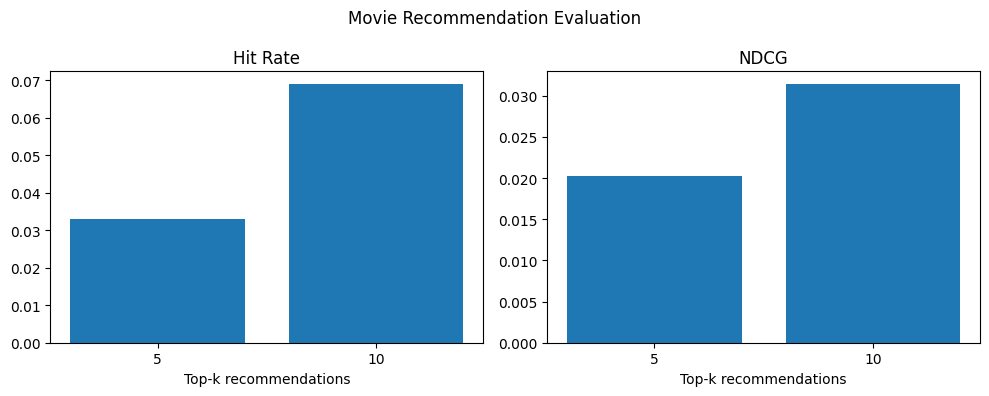

Project files saved to: /content/cognevance_movie_recommendation_system
ZIP file ready: /content/cognevance_movie_recommendation_system.zip


In [38]:
from pathlib import Path
import zipfile
import matplotlib.pyplot as plt

project_dir = Path("/content/cognevance_movie_recommendation_system")
results_dir = project_dir / "results"
charts_dir = project_dir / "charts"

results_dir.mkdir(parents=True, exist_ok=True)
charts_dir.mkdir(parents=True, exist_ok=True)

# Save evaluation results and dataset files.
evaluation_results.to_csv(results_dir / "evaluation_metrics.csv", index=False)
ratings.to_csv(project_dir / "ratings.csv", index=False)
movies.to_csv(project_dir / "movies.csv", index=False)

# Save a chart of the measured ranking metrics.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(evaluation_results["k"].astype(str), evaluation_results["hit_rate"])
axes[0].set_title("Hit Rate")
axes[0].set_xlabel("Top-k recommendations")

axes[1].bar(evaluation_results["k"].astype(str), evaluation_results["ndcg"])
axes[1].set_title("NDCG")
axes[1].set_xlabel("Top-k recommendations")

fig.suptitle("Movie Recommendation Evaluation")
fig.tight_layout()
fig.savefig(charts_dir / "evaluation_metrics.png", dpi=150, bbox_inches="tight")
plt.show()

# Build report text from the actual evaluation table.
row5 = evaluation_results.loc[evaluation_results["k"] == 5].iloc[0]
row10 = evaluation_results.loc[evaluation_results["k"] == 10].iloc[0]

report = f"""# Movie Recommendation System — Project Report

## Objective
Build and evaluate a user-based collaborative filtering recommender using the MovieLens small ratings dataset.

## Method
The evaluation holds out each user's latest recorded rating. The recommender is built using the remaining ratings only. User similarities are calculated from mean-centered ratings. Movies already rated by a user are excluded from that user's recommendations.

A held-out movie rated 4 or higher is treated as relevant. We report Hit Rate, Precision, Recall, and NDCG at 5 and 10 recommendations.

## Results

| Top-k | Evaluated users | Hit Rate | Precision | Recall | NDCG |
|---:|---:|---:|---:|---:|---:|
| 5 | {int(row5["evaluated_users"])} | {row5["hit_rate"]:.4f} | {row5["precision"]:.4f} | {row5["recall"]:.4f} | {row5["ndcg"]:.4f} |
| 10 | {int(row10["evaluated_users"])} | {row10["hit_rate"]:.4f} | {row10["precision"]:.4f} | {row10["recall"]:.4f} | {row10["ndcg"]:.4f} |

## Interpretation
The model's hit rate is higher at 10 recommendations than at 5, as expected when users receive a longer list. The measured hit rates are modest, so these results should be presented as a baseline experiment rather than evidence of a production-ready recommender.

## Limitations
- This is a single holdout evaluation, not repeated cross-validation.
- It tests users with prior ratings and does not measure recommendations for entirely new users.
- MovieLens is a small public dataset; results may not generalize to other users or catalogs.
- The evaluation uses each user's latest rating as the held-out item and treats ratings of 4 or higher as relevant.
"""

readme = """# Movie Recommendation System

A user-based collaborative filtering project using the MovieLens small ratings dataset.

## Notebook
Open `movie_recommendation_system.ipynb` in Google Colab and run the cells from top to bottom.

## Workflow
1. Load MovieLens movies and ratings.
2. Explore the data and rating patterns.
3. Build a user-based collaborative filtering recommender.
4. Evaluate with a per-user latest-rating holdout split.
5. Save metrics, chart, and report.

## Technologies
- Python
- pandas and NumPy
- scikit-learn
- Matplotlib
- Google Colab

## Results
See `results/evaluation_metrics.csv`, `charts/evaluation_metrics.png`, and `PROJECT_REPORT.md`.

## Dataset
MovieLens latest-small dataset from GroupLens:
https://grouplens.org/datasets/movielens/latest/

The included `ratings.csv` and `movies.csv` are the dataset files used by the notebook.

## Limitations
The evaluation is a single holdout experiment on users with prior ratings. Results are modest and may not generalize to new users or other datasets.
"""

(project_dir / "PROJECT_REPORT.md").write_text(report, encoding="utf-8")
(project_dir / "README.md").write_text(readme, encoding="utf-8")

zip_path = Path("/content/cognevance_movie_recommendation_system.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for file_path in project_dir.rglob("*"):
        if file_path.is_file():
            archive.write(file_path, file_path.relative_to(project_dir.parent))

print("Project files saved to:", project_dir)
print("ZIP file ready:", zip_path)

In [40]:
from pathlib import Path
import zipfile
from google.colab import files

project_dir = Path("/content/cognevance_movie_recommendation_system")
zip_path = Path("/content/cognevance_movie_recommendation_system.zip")

print("Project files:")
for path in sorted(project_dir.rglob("*")):
    if path.is_file():
        print(path.relative_to(project_dir))

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in project_dir.rglob("*"):
        if path.is_file():
            archive.write(path, path.relative_to(project_dir.parent))

print("\nStarting ZIP download...")
files.download(str(zip_path))

Project files:
PROJECT_REPORT.md
README.md
charts/evaluation_metrics.png
movies.csv
ratings.csv
results/evaluation_metrics.csv

Starting ZIP download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>